# Original UTM raster vs. established compressors (no homemade codec)

Companion to `hpx_codec_bench.ipynb`, but on the **other side of the
resampling**: instead of compressing the HEALPix-tile representation, this
crops the ORIGINAL native-resolution UTM raster (Sentinel-2 B04, already
cached on disk as `data/<scene>_data.zarr` by `compress_test.ipynb`) down to
the exact geographic footprint of the same dominant HEALPix tile, and
compresses *that* -- so the two notebooks' RD results are directly
comparable: same ground footprint, HEALPix-resampled grid vs. native UTM
grid.

Two changes from `hpx_codec_bench.ipynb`:

- **No homemade codec.** `grad_dwt_zlib`/`grad_dwt_spiht` are dropped
  entirely -- conclusion after extensive tuning is that none of the
  in-house entropy coders (zlib, zero-tree, SPIHT) get anywhere close to
  established libraries even at high bitrate/near-lossless settings, so
  this benchmark only uses well-established, independently-maintained
  compressors (zfp, SZ3, JPEG 2000, JPEG XL, a plain DWT+zstd baseline).
- **Real geographic footprint, not a pixel-count heuristic.** The footprint
  crop uses the ACTUAL lon/lat of every fine-level (order 20) HEALPix cell
  in the dominant tile (`healpix_geo.nested.healpix_to_lonlat(...,
  ellipsoid="WGS84")` -- matching the ellipsoid the original UTM->HEALPix
  resampling already used by default), transformed into the scene's own UTM
  CRS, giving a real bounding box to crop the native raster to. This is
  more precise than the `ratio_20` same-pixel-count heuristic used
  elsewhere in this project.

Note `ellipsoid=True` is not a valid argument to `healpix_geo` -- it takes a
named ellipsoid string (`"WGS84"` or `"sphere"`); passing `True` raises a
`TypeError`. `"WGS84"` is used here to match
`healpix_resample.KNeighborsResampler`'s default, so the geometry is
self-consistent with how `data/all_image_cell.npy` was generated.

In [1]:
%load_ext autoreload
%autoreload 2

# Minimal, independent deps -- this notebook does NOT import `hcc` at all
# (no homemade codec involved), so it doesn't need zarr>=3 or a kernel
# restart the way hpx_codec_bench.ipynb's first cell does.
try:
    import xarray as xr
except ImportError:
    !pip install xarray-eopf
    import xarray as xr
try:
    import pyproj
except ImportError:
    !pip install pyproj
    import pyproj
try:
    import healpix_geo
except ImportError:
    !pip install healpix-geo
    import healpix_geo
try:
    import pywt
except ImportError:
    !pip install PyWavelets
    import pywt
try:
    import zfpy
except ImportError:
    !pip install zfpy
    import zfpy
try:
    import pysz
except ImportError:
    !pip install pysz
    import pysz
try:
    import zstandard
except ImportError:
    !pip install zstandard


In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
FIGURES_DIR = Path("figures")
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

# --- colour-blind-safe palette (Okabe & Ito, 2008) + distinct markers -------
CODEC_STYLE = {
    "zfp":               dict(color="#0072B2", marker="o"),  # blue
    "sz3":                dict(color="#D55E00", marker="s"),  # vermillion
    "jpeg2000_lossy":     dict(color="#009E73", marker="^"),  # bluish green
    "jpeg2000_lossless":  dict(color="#000000", marker="*"),  # black
    "jpegxl_lossy":       dict(color="#CC79A7", marker="D"),  # reddish purple
    "jpegxl_lossless":    dict(color="#E69F00", marker="P"),  # orange
    "dwt_zstd":           dict(color="#56B4E9", marker="v"),  # sky blue
}
plt.rcParams["figure.figsize"] = (8, 5.5)
plt.rcParams["font.size"] = 11

In [6]:
# --- crop a UTM-native, axis-aligned square of EQUAL GROUND AREA to the
# HEALPix carrier tile, centred on the tile's centroid -----------------------
# Earlier version of this cell used an axis-aligned BOUNDING BOX around the
# HEALPix tile's (diamond-shaped, rotated) footprint. That is wrong: a HEALPix
# level-20 tile projected into lon/lat is a rotated square, and its bounding
# box necessarily includes ~2x more UTM pixels than the tile's true footprint
# (confirmed on real data: the old crop was ~900-940 px/side, not the ~637
# px/side a footprint-exact comparison requires -- see project history).
#
# Rather than mask that rotated diamond into a rectangle (which needs filler
# values in the ~50% of the box outside the diamond, and those filler values
# would still cost real compressed bytes unless artificially trivial), we
# instead compare each grid in its OWN native geometry: the HEALPix tile
# (a rotated square in its own frame) against a genuine axis-aligned UTM
# square of the SAME GROUND AREA, centred on the same location. Because
# HEALPix is equal-area, this reference side length is an exact geometric
# constant, not something to (re)derive per scene:
#   side_px = 1024 * delta_eq(level=20) / 10m ~= 636.7 -> 637
# (delta_eq from eq. (1) of the paper, R_earth = 6371008.8 m).
#
# Reuses data/all_image_cell.npy (cell ids only -- we don't need the
# HEALPix-resampled values here) and the already-cached
# data/<scene>_data.zarr stores compress_test.ipynb writes. No network
# access, no re-derivation.
SCENE_NAMES = ["urban", "water", "forest", "agriculture", "snow_ice", "clouds", "ocean"]
LEVEL = 20  # must match the level used when all_image_cell.npy was built

R_EARTH = 6371008.8  # m, matches eq. (1) of the paper
DELTA_EQ_20 = np.sqrt(4 * np.pi * R_EARTH**2 / (12 * 4**LEVEL))  # m, HEALPix level-20 equal-area cell width
SIDE_PX = int(round(1024 * DELTA_EQ_20 / 10.0))  # native 10 m UTM pixels; ~637
assert SIDE_PX % 2 == 1, "expected an odd side length for a clean centred window"
HALF = SIDE_PX // 2
print(f"delta_eq(20) = {DELTA_EQ_20:.3f} m -> reference UTM square side = {SIDE_PX} px "
      f"({SIDE_PX * SIDE_PX * 4 / 1e6:.3f} MB raw, fixed across all scenes)")

cell_path = DATA_DIR / "all_image_cell.npy"
if not cell_path.exists():
    raise FileNotFoundError(
        f"Expected {cell_path} -- run compress_test.ipynb's cell 10 (data "
        "derivation) once first; this notebook only reuses its cached "
        "cell-id output, plus the data/<scene>_data.zarr stores it also "
        "writes (compress_test.ipynb cell 6)."
    )
cell_ids_all = np.load(cell_path)
assert cell_ids_all.shape[0] == len(SCENE_NAMES), (
    f"cell_ids_all.shape[0]={cell_ids_all.shape[0]} != len(SCENE_NAMES)="
    f"{len(SCENE_NAMES)} -- SCENE_NAMES must match the row order used when "
    "all_image_cell.npy was written."
)

UTM_TILES: dict[str, np.ndarray] = {}
RAW_BYTES: dict[str, int] = {}       # now a FIXED constant across scenes, same as HPX
CROP_DIAGNOSTICS: dict[str, dict] = {}  # kept for the contour figure in the next cell

for k, name in enumerate(SCENE_NAMES[0:1]):
    cell_ids = cell_ids_all[k].astype(np.uint64)
    lon, lat = healpix_geo.nested.healpix_to_lonlat(cell_ids, LEVEL, ellipsoid="WGS84")
    lon_hpx = (lon + 360) % 360
    lon_c, lat_c = float(lon_hpx.mean()), float(lat.mean())

    zarr_path = DATA_DIR / f"{name}_data.zarr"
    dt = xr.open_datatree(str(zarr_path), engine="zarr", consolidated=False, chunks={})
    b04 = dt["b04"]
    lon_utm = (b04.longitude.values + 360) % 360
    lat_utm = b04.latitude.values

    # nearest native UTM pixel to the HEALPix tile's centroid, found directly
    # in the raster's own (lon, lat) fields -- no separate CRS transform
    # needed, and this is exact regardless of the scene's UTM zone/CRS.
    cos_lat = np.cos(np.radians(lat_c))
    d2 = (lon_utm - lon_c) ** 2 * cos_lat**2 + (lat_utm - lat_c) ** 2
    ix, iy = np.unravel_index(np.argmin(d2), d2.shape)

    x1, x2 = ix - HALF, ix - HALF + SIDE_PX
    y1, y2 = iy - HALF, iy - HALF + SIDE_PX
    ny, nx = b04.shape
    if x1 < 0 or y1 < 0 or x2 > ny or y2 > nx:
        raise ValueError(
            f"{name}: {SIDE_PX}x{SIDE_PX} UTM square centred on the HEALPix tile "
            f"centroid falls outside the available raster (raster shape "
            f"{b04.shape}, requested rows [{x1}:{x2}) cols [{y1}:{y2})) -- the "
            "cached scene extent is too small for a full reference square; "
            "widen the original UTM extraction in compress_test.ipynb for "
            "this scene."
        )

    crop = b04[x1:x2, y1:y2].values.astype(np.float32)
    if np.isnan(crop).any():
        crop = np.where(np.isnan(crop), np.float32(np.nanmean(crop)), crop)
    assert crop.shape == (SIDE_PX, SIDE_PX)

    UTM_TILES[name] = crop
    RAW_BYTES[name] = crop.nbytes
    CROP_DIAGNOSTICS[name] = dict(
        lon_hpx=lon_hpx, lat_hpx=lat, lon_c=lon_c, lat_c=lat_c,
        lon_utm_full=lon_utm, lat_utm_full=lat_utm,
        ix=ix, iy=iy, x1=x1, x2=x2, y1=y1, y2=y2,
    )
    print(f"{name:<12} UTM square {SIDE_PX}x{SIDE_PX} px ({crop.nbytes / 1e6:6.3f} MB)  "
          f"centroid lon={lon_c:.4f} lat={lat_c:.4f}")


delta_eq(20) = 6.218 m -> reference UTM square side = 637 px (1.623 MB raw, fixed across all scenes)
urban        UTM square 637x637 px ( 1.623 MB)  centroid lon=2.2907 lat=48.8548


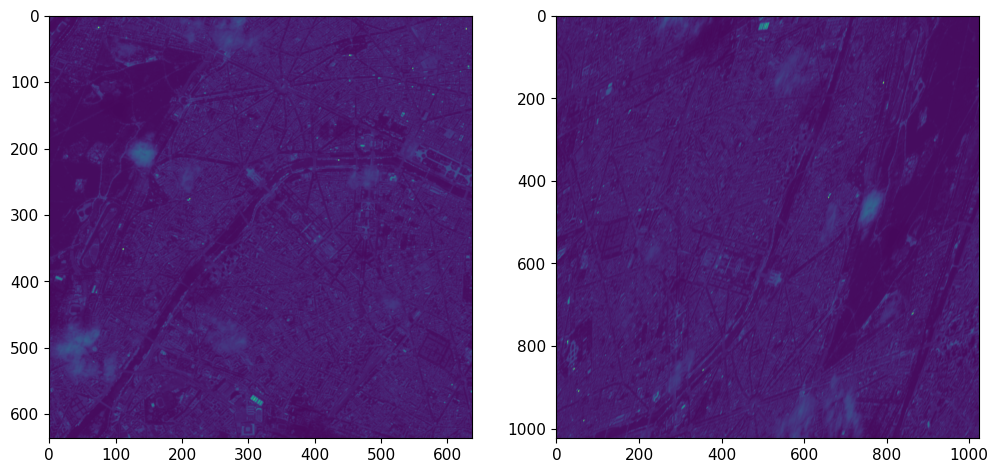

In [9]:
import sys
try:
    import hcc  # noqa: F401
except ModuleNotFoundError:
    repo = Path.cwd().parent
    if (repo / "hcc" / "__init__.py").exists():
        sys.path.insert(0, str(repo))
        
from hcc.compression.zorder import expand_tile

im = np.load(DATA_DIR / "all_image_data.npy")
image=0
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(crop,vmin=crop.min(),vmax=crop.max())
plt.subplot(1,2,2)
plt.imshow(expand_tile(im[image]),vmin=crop.min(),vmax=crop.max())

def encode_sz3(tile, abs_error):
    from pysz import sz as _sz, szConfig, szErrorBoundMode
    tile = np.ascontiguousarray(np.asarray(tile, dtype=np.float32))
    config = szConfig()
    config.errorBoundMode = szErrorBoundMode.ABS
    config.absErrorBound = float(abs_error)
    t0 = time.perf_counter()
    compressed, _ = _sz.compress(tile, config)
    t1 = time.perf_counter()
    dec, _ = _sz.decompress(compressed, np.float32, tile.shape)
    t2 = time.perf_counter()
    total_bytes = int(getattr(compressed, "nbytes", None) or len(compressed))
    return CodecRunResult("sz3", dict(abs_error=float(abs_error)), total_bytes, t1 - t0, t2 - t1,
                           np.asarray(dec, dtype=np.float32))

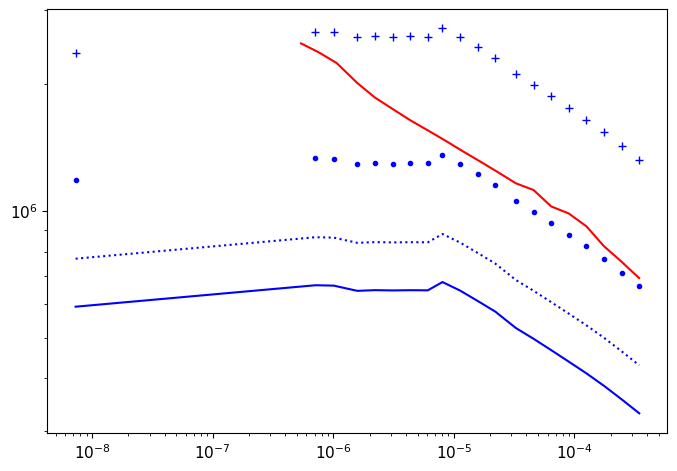

In [10]:

tab_abs=[1e-6*1.4**k for k in range(20)]
rmse_utm=[]
rmse_healpix=[]
size_utm=[]
size_healpix=[]

tmp=expand_tile(im[image]).astype('float32')
for abs_err in tab_abs:
    d1=encode_sz3(crop,abs_err)
    d2=encode_sz3(tmp,abs_err)
    rmse_utm.append(np.std(d1.reconstruction-crop))
    rmse_healpix.append(np.std(d2.reconstruction-tmp))
    size_utm.append(d1.total_bytes)
    size_healpix.append(d2.total_bytes)
    
plt.loglog(rmse_utm,size_utm,color='b')
plt.loglog(rmse_utm,np.array(size_utm)*1.3,':',color='b')
plt.loglog(rmse_utm,np.array(size_utm)*2,'.',color='b')
plt.loglog(rmse_utm,np.array(size_utm)*4,'+',color='b')
plt.loglog(rmse_healpix,size_healpix,color='r')

(2.584169810902262, (1024, 1024), 405769)

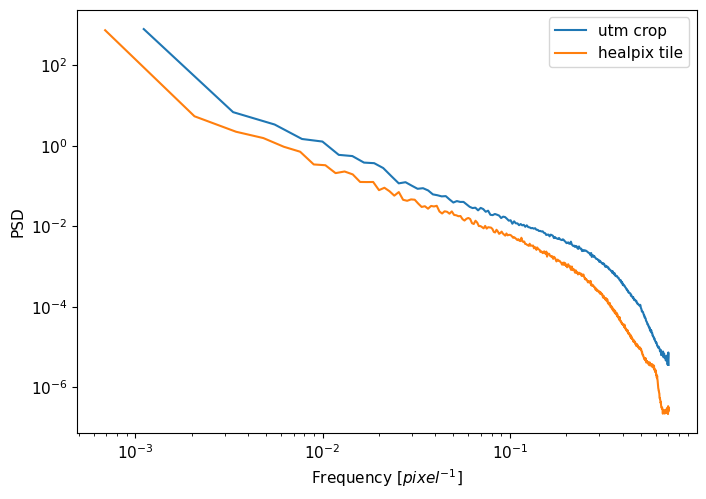

In [16]:
from healpix_analyse.ps import ps

im = np.load(DATA_DIR / "all_image_data.npy")
tmp=expand_tile(im[0]).astype('float32')
v,y=ps(crop)
v2,y2=ps(tmp)

plt.loglog(v,y,label='utm crop')
plt.loglog(v2,y2/((1000/637)**2),label='healpix tile')
plt.xlabel(r'Frequency $[pixel^{-1}]$')
plt.ylabel('PSD')
plt.legend()
tmp.nbytes/crop.nbytes,tmp.shape,crop.shape[0]*crop.shape[1]

In [ ]:
plt.imshow(expand_tile(im[image])[0:128,0:128])

In [ ]:
# --- Diagnostic figure: HEALPix footprint vs. the new UTM reference square,
# one panel per scene, all scenes on the same row, as requested. Shows the
# full locally available UTM raster extent (grey), the HEALPix tile's true
# (rotated, diamond-shaped) footprint (blue fill), and the axis-aligned
# 637x637 reference square actually compressed on the UTM side (red outline)
# -- so the size mismatch between the two (blue area << grey bounding area,
# red square matched in AREA but not SHAPE to the blue diamond) is visible
# directly, not just asserted in the text.
n_scenes = len(SCENE_NAMES)
fig, axes = plt.subplots(1, n_scenes, figsize=(4.2 * n_scenes, 4.6))
axes = np.atleast_1d(axes)

for ax, name in zip(axes, SCENE_NAMES):
    d = CROP_DIAGNOSTICS[name]
    lon_full, lat_full = d["lon_utm_full"], d["lat_utm_full"]
    lon_c,lat_c = d["lon_c"], d["lat_c"]
    d2 = (lon_full - lon_c) ** 2 * cos_lat**2 + (lat_full - lat_c) ** 2
    
    #ax.scatter(lon_full, lat_full, s=1, color="0.6", marker=".", rasterized=True,
    #           label="UTM raster extent (local)")
    #ax.scatter(d["lon_c"], d["lat_c"], s=10, color='r', marker="+", rasterized=True,
    #           label="HEALPix center")

    # HEALPix tile's true footprint: convex hull of its level-20 cell centres
    from scipy.spatial import ConvexHull
    pts = np.column_stack([d["lon_hpx"], d["lat_hpx"]])
    hull = ConvexHull(pts)
    poly = pts[hull.vertices]
    ax.fill(poly[:, 0], poly[:, 1], color="#0072B2", alpha=0.85,
             edgecolor="black", linewidth=0.5, label="HEALPix tile footprint")

    # the new 637x637 UTM reference square actually compressed (axis-aligned
    # in index space == axis-aligned in this scene's UTM CRS)
    x1, x2, y1, y2 = d["x1"], d["x2"], d["y1"], d["y2"]
    
    #ax.scatter(lon_full[(x1+x2)//2,(y1+y2)//2], lat_full[(x1+x2)//2,(y1+y2)//2], s=10, color='b', marker="+", rasterized=True,
    #           label="UTM center")
    corners_lon = lon_full[[x1, x1, x2 - 1, x2 - 1, x1], [y1, y2 - 1, y2 - 1, y1, y1]]
    corners_lat = lat_full[[x1, x1, x2 - 1, x2 - 1, x1], [y1, y2 - 1, y2 - 1, y1, y1]]
    ax.plot(corners_lon, corners_lat, color="#D55E00", linewidth=2.0,
            label="UTM reference square (637x637, equal area)")

    ax.set_title(name, fontsize=14)
    ax.set_aspect("equal")
    ax.tick_params(labelsize=10)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.05),
           fontsize=9, frameon=False)
fig.suptitle("HEALPix footprint vs. equal-area UTM reference square, per scene", y=1.03)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_utm_crop_footprints.pdf", bbox_inches="tight")
fig.savefig(FIGURES_DIR / "fig_utm_crop_footprints.png", dpi=150, bbox_inches="tight")
plt.show()


In [8]:
# --- codec adapters ----------------------------------------------------------
from dataclasses import dataclass


@dataclass
class CodecRunResult:
    codec: str
    config: dict
    total_bytes: int
    encode_seconds: float
    decode_seconds: float
    reconstruction: np.ndarray


def _rmse(a, b):
    mask = np.isfinite(a) & np.isfinite(b)
    return float(np.sqrt(np.mean((a[mask] - b[mask]) ** 2))) if mask.any() else np.nan


def encode_zfp(tile, *, tolerance):
    import zfpy
    tile = np.asarray(tile, dtype=np.float32)
    t0 = time.perf_counter()
    enc = zfpy.compress_numpy(tile, tolerance=float(tolerance))
    t1 = time.perf_counter()
    dec = zfpy.decompress_numpy(enc)
    t2 = time.perf_counter()
    return CodecRunResult("zfp", dict(tolerance=float(tolerance)), len(enc), t1 - t0, t2 - t1, dec)


def encode_sz3(tile, *, abs_error):
    from pysz import sz as _sz, szConfig, szErrorBoundMode
    tile = np.ascontiguousarray(np.asarray(tile, dtype=np.float32))
    config = szConfig()
    config.errorBoundMode = szErrorBoundMode.ABS
    config.absErrorBound = float(abs_error)
    t0 = time.perf_counter()
    compressed, _ = _sz.compress(tile, config)
    t1 = time.perf_counter()
    dec, _ = _sz.decompress(compressed, np.float32, tile.shape)
    t2 = time.perf_counter()
    total_bytes = int(getattr(compressed, "nbytes", None) or len(compressed))
    return CodecRunResult("sz3", dict(abs_error=float(abs_error)), total_bytes, t1 - t0, t2 - t1,
                           np.asarray(dec, dtype=np.float32))


def _to_u16(tile):
    tile = np.asarray(tile, dtype=np.float32)
    t_min, t_max = float(tile.min()), float(tile.max())
    span = (t_max - t_min) or 1.0
    return ((tile - t_min) / span * 65535).astype(np.uint16), t_min, span


def _from_u16(u16, t_min, span):
    return u16.astype(np.float32) / 65535.0 * span + t_min


def encode_jpeg2000_lossy(tile, *, quality):
    import io
    from PIL import Image
    u16, t_min, span = _to_u16(tile)
    factor = max(1, int(quality))  # never let it round to 0 (past bug, see main notebook)
    buf = io.BytesIO()
    t0 = time.perf_counter()
    Image.fromarray(u16).save(buf, format="jpeg2000", quality_mode="rates", quality_layers=[factor])
    t1 = time.perf_counter()
    total_bytes = buf.tell()
    buf.seek(0)
    dec_u16 = np.array(Image.open(buf), dtype=np.uint16)
    t2 = time.perf_counter()
    return CodecRunResult("jpeg2000_lossy", dict(quality=factor), total_bytes, t1 - t0, t2 - t1,
                           _from_u16(dec_u16, t_min, span))


def encode_jpeg2000_lossless(tile, **_ignored):
    import imagecodecs
    u16, t_min, span = _to_u16(tile)
    t0 = time.perf_counter()
    enc = imagecodecs.jpeg2k_encode(u16, level=0)
    t1 = time.perf_counter()
    dec_u16 = imagecodecs.jpeg2k_decode(enc)
    t2 = time.perf_counter()
    return CodecRunResult("jpeg2000_lossless", {}, len(enc), t1 - t0, t2 - t1,
                           _from_u16(dec_u16, t_min, span))


_jpegxl_warned = False


def encode_jpegxl_lossy(tile, *, level):
    # imagecodecs' `level` for jpegxl follows its shared 0-100 convention
    # across codecs (100 ~ visually lossless / near-lossless, not literally
    # lossless -- see encode_jpegxl_lossless for that). If the installed
    # imagecodecs version uses a different kwarg name, this fails loudly
    # once with a clear message instead of silently corrupting the sweep.
    global _jpegxl_warned
    import imagecodecs
    u16, t_min, span = _to_u16(tile)
    t0 = time.perf_counter()
    try:
        enc = imagecodecs.jpegxl_encode(u16, level=int(level))
    except TypeError as e:
        if not _jpegxl_warned:
            print(f"[jpegxl] encode signature mismatch ({e}) -- check your imagecodecs "
                  "version's jpegxl_encode kwargs and adjust this adapter. Skipping jpegxl.")
            _jpegxl_warned = True
        raise
    t1 = time.perf_counter()
    dec_u16 = imagecodecs.jpegxl_decode(enc)
    t2 = time.perf_counter()
    return CodecRunResult("jpegxl_lossy", dict(level=int(level)), len(enc), t1 - t0, t2 - t1,
                           _from_u16(dec_u16, t_min, span))


def encode_jpegxl_lossless(tile, **_ignored):
    import imagecodecs
    u16, t_min, span = _to_u16(tile)
    t0 = time.perf_counter()
    enc = imagecodecs.jpegxl_encode(u16, lossless=True)
    t1 = time.perf_counter()
    dec_u16 = imagecodecs.jpegxl_decode(enc)
    t2 = time.perf_counter()
    return CodecRunResult("jpegxl_lossless", {}, len(enc), t1 - t0, t2 - t1,
                           _from_u16(dec_u16, t_min, span))


def encode_dwt_zstd(tile, *, wavelet="db4", levels=4, quantize_bits):
    # Deliberately simple, well-known technique (PyWavelets + uniform
    # quantisation + zstd) -- a generic scale-correlation-exploiting
    # baseline, NOT the custom hcc SPIHT/zero-tree machinery this notebook
    # is moving away from.
    import pywt
    import zstandard as zstd
    tile = np.asarray(tile, dtype=np.float32)
    t0 = time.perf_counter()
    coeffs = pywt.wavedec2(tile, wavelet=wavelet, level=levels, mode="periodization")
    arr, slices = pywt.coeffs_to_array(coeffs)
    max_level = (1 << (quantize_bits - 1)) - 1
    scale = float(np.max(np.abs(arr))) or 1.0
    dtype_q = np.int8 if quantize_bits <= 8 else np.int16
    q = np.round(np.clip(arr / scale * max_level, -max_level, max_level)).astype(dtype_q)
    payload = zstd.ZstdCompressor(level=19).compress(q.tobytes())
    t1 = time.perf_counter()
    total_bytes = len(payload) + 4  # + float32 scale sidecar
    q2 = np.frombuffer(zstd.ZstdDecompressor().decompress(payload), dtype=dtype_q).reshape(arr.shape)
    arr2 = (q2.astype(np.float32) / max_level * scale).astype(np.float64)
    coeffs2 = pywt.array_to_coeffs(arr2, slices, output_format="wavedec2")
    dec = pywt.waverec2(coeffs2, wavelet=wavelet, mode="periodization").astype(np.float32)
    # periodization mode internally rounds odd dimensions up to the next
    # even number and does NOT crop back down on reconstruction (verified:
    # a (1070, 755) input round-trips to (1070, 756) regardless of levels)
    # -- harmless on the fixed 1024x1024 HEALPix tiles elsewhere in this
    # project (always even), but real UTM crops are arbitrary shapes.
    if dec.shape != tile.shape:
        dec = dec[:tile.shape[0], :tile.shape[1]]
    t2 = time.perf_counter()
    return CodecRunResult("dwt_zstd", dict(wavelet=wavelet, levels=levels, quantize_bits=quantize_bits),
                           total_bytes, t1 - t0, t2 - t1, dec)


def encode_uncompressed(tile, **_ignored):
    tile = np.asarray(tile, dtype=np.float32)
    return CodecRunResult("uncompressed", {}, tile.nbytes, 0.0, 0.0, tile.copy())

In [ ]:
# --- sweeps (kept modest -- this notebook is meant to iterate fast) --------
ZFP_SWEEP = [dict(tolerance=float(v)) for v in np.logspace(-5, -1, 8)]
SZ3_SWEEP = [dict(abs_error=float(v)) for v in np.logspace(-5, -1, 8)]
JPEG2000_LOSSY_SWEEP = [dict(quality=q) for q in (1, 2, 3, 5, 8, 12, 20, 35, 60, 100)]
JPEGXL_LOSSY_SWEEP = [dict(level=lv) for lv in (10, 25, 40, 55, 68, 78, 86, 92, 96, 99)]
DWT_ZSTD_SWEEP = [dict(quantize_bits=b) for b in (4, 6, 8, 10, 12, 14, 16)]

CODEC_RUNS = {
    "zfp": (encode_zfp, ZFP_SWEEP),
    "sz3": (encode_sz3, SZ3_SWEEP),
    "jpeg2000_lossy": (encode_jpeg2000_lossy, JPEG2000_LOSSY_SWEEP),
    "jpeg2000_lossless": (encode_jpeg2000_lossless, [dict()]),
    "jpegxl_lossy": (encode_jpegxl_lossy, JPEGXL_LOSSY_SWEEP),
    "jpegxl_lossless": (encode_jpegxl_lossless, [dict()]),
    "dwt_zstd": (encode_dwt_zstd, DWT_ZSTD_SWEEP),
    "uncompressed": (encode_uncompressed, [dict()]),
}

rows = []
for scene, tile in UTM_TILES.items():
    for codec, (fn, sweep) in CODEC_RUNS.items():
        for cfg in sweep:
            try:
                run = fn(tile, **cfg)
            except Exception as e:
                print(f"[skip] {codec} {cfg} on {scene}: {type(e).__name__}: {e}")
                continue
            rmse = _rmse(tile, run.reconstruction)
            rows.append(dict(
                scene=scene, codec=run.codec, config_json=json.dumps(run.config),
                total_bytes=run.total_bytes, rmse=rmse,
                encode_seconds=run.encode_seconds, decode_seconds=run.decode_seconds,
            ))
    print(f"done: {scene}  ({tile.shape[0]}x{tile.shape[1]})")

rd_df = pd.DataFrame(rows)
rd_df.to_csv(RESULTS_DIR / "utm_codec_bench.csv", index=False)
print(rd_df.shape, "rows saved to results/utm_codec_bench.csv")
rd_df.head()

In [ ]:
# --- Diagnostic: per-scene RD curves (size vs RMSE), one panel per scene --
# Unlike hpx_codec_bench.ipynb, crop sizes differ per scene here, so each
# panel normalises by ITS OWN scene's raw byte count (RAW_BYTES[scene]), not
# a single shared reference.
codec = {}
for k in rd_df.codec:
    codec[k] = 1
scene = {}
for k in rd_df.scene:
    scene[k] = 1
scene = [k for k in scene]
codec = [k for k in codec]

LOSSLESS_CODECS = {"jpeg2000_lossless", "jpegxl_lossless"}

n_cols = 3
n_rows = int(np.ceil(len(scene) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.3 * n_cols, 3.4 * n_rows))
axes = np.atleast_1d(axes).ravel()

for ax, sc in zip(axes, scene):
    raw_bytes_sc = RAW_BYTES[sc]
    msize = 200
    for cd in codec:
        if cd == "uncompressed":
            continue
        g = rd_df[(rd_df.scene == sc) & (rd_df.codec == cd)]
        g = g.replace([np.inf, -np.inf], np.nan).dropna(subset=["rmse", "total_bytes"])
        g = g[g["rmse"] > 0]
        if g.empty:
            continue
        style = CODEC_STYLE.get(cd, dict(color="grey", marker="x"))
        if cd in LOSSLESS_CODECS or len(g) < 2:
            ax.scatter(g["rmse"], g["total_bytes"] , color=style["color"],
                       marker=style["marker"], s=msize, linewidth=0.7, zorder=5, label=cd)
            msize *= 0.5
        else:
            g = g.sort_values("rmse")
            ax.plot(g["rmse"], g["total_bytes"], color=style["color"],
                    marker=style["marker"], markersize=5, linewidth=1.4, label=cd)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(sc, fontsize=10)
    ax.set_ylim(3e2,3e6)
    ax.grid(True, which="both", linewidth=0.3, alpha=0.4)

for ax in axes[len(scene):]:
    ax.axis("off")

fig.supxlabel("RMSE (native UTM grid, log scale)")
fig.supylabel("Compressed size / this scene's raw crop size (log scale)")
handles, labels = [], []
for ax in axes[:len(scene)]:
    h, l = ax.get_legend_handles_labels()
    for hi, li in zip(h, l):
        if li not in labels:
            handles.append(hi)
            labels.append(li)
fig.legend(handles, labels, loc="lower center", ncol=min(len(labels), 4),
           bbox_to_anchor=(0.5, -0.04), fontsize=9, frameon=False)
fig.suptitle("Rate-distortion curves per scene -- native UTM crop", y=1.02)
fig.tight_layout(rect=[0, 0.06, 1, 1])
fig.savefig(FIGURES_DIR / "fig_utm_rd_curves_per_scene.pdf", bbox_inches="tight")
fig.savefig(FIGURES_DIR / "fig_utm_rd_curves_per_scene.png", dpi=150, bbox_inches="tight")
plt.show()

## Cross-source comparison (HEALPix vs. UTM) moved to `stats_significance.ipynb`

This notebook used to compute its own cross-source comparison and write
`figures/fig_storage_at_constant_rmse.{pdf,png}` /
`figures/fig_error_at_constant_size.{pdf,png}` directly here. That duplicated
the same comparison logic that also lives in `stats_significance.ipynb`, and
the two drifted out of sync: this notebook's copy never got the
$\gamma_{\mathrm{UTM}}$ fix (it normalized by each source's own raw size with
no operational-overhead correction on the main curve, plus a `*1.3` overlay
applied in the wrong direction on the lossless points), while
`stats_significance.ipynb` did. Running this notebook top-to-bottom was
silently overwriting a correct figure in `test/figures/` with a stale,
incorrect one that disagreed with the one actually used in the paper
(`tex/figures/`, written only by `stats_significance.ipynb`).

**To regenerate Tables III-VI, Figure 1, and the significance tests**, run
`stats_significance.ipynb` after this notebook (it only needs this
notebook's `results/utm_codec_bench.csv` and `hpx_codec_bench.ipynb`'s
`results/hpx_codec_bench.csv` -- both already written above). Do not
regenerate the cross-source comparison here; this notebook's own remaining
job is just producing `results/utm_codec_bench.csv` and the per-scene
diagnostics above (crop footprints, per-scene RD curves).